In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Загружаем обработанные данные из первой лабораторной
df = pd.read_csv('processed_spotify_data.csv')

# 2. Удаляем текстовые ID и названия, которые не нужны для обучения
columns_to_drop_text = ['track_id', 'track_name', 'artist_name', 'album_name', 'release_date']
columns_to_drop_text = [col for col in columns_to_drop_text if col in df.columns]
df = df.drop(columns=columns_to_drop_text)

# 3. АВТОМАТИЧЕСКИ находим все оставшиеся текстовые столбцы (тип 'object')
text_columns = df.select_dtypes(include=['object']).columns.tolist()
print(f"Найдены текстовые столбцы: {text_columns}")

# 4. Применяем One-Hot Encoding ко всем найденным текстовым столбцам
# drop_first=True убирает первый столбец каждой категории (защита от мультиколлинеарности)
if text_columns:
    df = pd.get_dummies(df, columns=text_columns, drop_first=True)
    print(f"После кодирования в датафрейме {df.shape[1]} столбцов.")
else:
    print("Текстовых столбцов не найдено, кодирование не требуется.")

# 5. Проверяем, что не осталось текстовых столбцов
remaining_text = df.select_dtypes(include=['object']).columns.tolist()
print(f"Осталось текстовых столбцов: {remaining_text}")

# 6. ОПРЕДЕЛЯЕМ ЦЕЛЬ (y)
y = df['stream_count']

# 7. ОПРЕДЕЛЯЕМ ПРИЗНАКИ (X)
# Удаляем целевую переменную и её производные (MinMax, логарифм)
X = df.drop(columns=['stream_count', 'stream_count_MinMax', 'log_stream_count'], errors='ignore')

# 8. РАЗДЕЛЯЕМ ВЫБОРКУ
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nРазмер X_train: {X_train.shape}")
print(f"Размер X_test: {X_test.shape}")

Найдены текстовые столбцы: ['release_day_of_week', 'popularity_category', 'loudness_category', 'release_quarter']
После кодирования в датафрейме 124 столбцов.
Осталось текстовых столбцов: []

Размер X_train: (40000, 121)
Размер X_test: (10000, 121)


In [9]:
from sklearn.linear_model import LinearRegression

# 1. Создаем объект модели
linear_model = LinearRegression()

# 2. ОБУЧАЕМ модель на тренировочных данных
linear_model.fit(X_train, y_train)

# 3. ДЕЛАЕМ ПРЕДСКАЗАНИЯ на тестовых данных
y_pred_test = linear_model.predict(X_test)

print("Модель обучена и предсказания сделаны!")
print(f"Пример реального значения: {y_test.iloc[0]:,.2f}")
print(f"Пример предсказания модели: {y_pred_test[0]:,.2f}")

Модель обучена и предсказания сделаны!
Пример реального значения: 6,504.00
Пример предсказания модели: 58,562.73


In [10]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error

# Считаем метрики
MSE = mean_squared_error(y_test, y_pred_test)
RMSE = root_mean_squared_error(y_test, y_pred_test)
MAE = mean_absolute_error(y_test, y_pred_test)

print(f"MSE: {MSE:,.2f}")
print(f"RMSE: {RMSE:,.2f}")
print(f"MAE: {MAE:,.2f}")

# Посмотрим на первые 5 сравнений
comparison = pd.DataFrame({'Реальные': y_test[:5].values, 'Предсказанные': y_pred_test[:5]})
print("\nСравнение реальных и предсказанных значений:")
print(comparison)

MSE: 197,014,003,450.51
RMSE: 443,862.60
MAE: 117,355.61

Сравнение реальных и предсказанных значений:
   Реальные  Предсказанные
0    6504.0   58562.728513
1  245494.0  164583.383582
2   12928.0   28772.061670
3    2492.0   34731.333082
4   15400.0  -38590.596763


In [11]:
from sklearn.linear_model import Ridge

# Создаем и обучаем Ridge-модель
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)

# Считаем RMSE для Ridge
RMSE_ridge = root_mean_squared_error(y_test, y_pred_ridge)
print(f"RMSE для Ridge: {RMSE_ridge:,.2f}")

# Сравниваем с обычной линейной регрессией
RMSE_linear = root_mean_squared_error(y_test, y_pred_test)
print(f"RMSE для Linear: {RMSE_linear:,.2f}")

RMSE для Ridge: 443,757.04
RMSE для Linear: 443,862.60


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# 1. Определяем X и y для классификации
# Целевая переменная — is_explicit_bool (True/False)
y_cls = df['is_explicit_bool']

# X — все столбцы, кроме целевой переменной и производных от stream_count
X_cls = df.drop(columns=['is_explicit_bool', 'stream_count', 'stream_count_MinMax', 'log_stream_count'], errors='ignore')

# 2. Разделяем данные заново
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

# 3. Создаем и обучаем модель
logreg_model = LogisticRegression(max_iter=1000)
logreg_model.fit(X_train_cls, y_train_cls)

# 4. Делаем предсказание
y_pred_cls = logreg_model.predict(X_test_cls)

print("Модель классификации обучена!")
print(f"Пример реального класса: {y_test_cls.iloc[0]}")
print(f"Пример предсказания модели: {y_pred_cls[0]}")

Модель классификации обучена!
Пример реального класса: False
Пример предсказания модели: False


Accuracy (Доля правильных ответов): 1.0000

Матрица ошибок (Confusion Matrix):
[[7449    0]
 [   0 2551]]


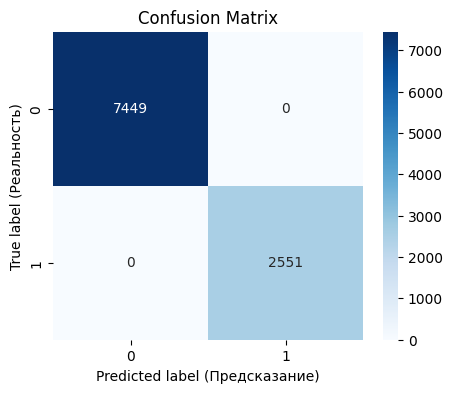


Отчет по классификации:
              precision    recall  f1-score   support

       False       1.00      1.00      1.00      7449
        True       1.00      1.00      1.00      2551

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



In [15]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Accuracy
accuracy = accuracy_score(y_test_cls, y_pred_cls)
print(f"Accuracy (Доля правильных ответов): {accuracy:.4f}")

# 2. Матрица ошибок
cm = confusion_matrix(y_test_cls, y_pred_cls)
print("\nМатрица ошибок (Confusion Matrix):")
print(cm)

# 3. Визуализация матрицы ошибок
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('True label (Реальность)')
plt.xlabel('Predicted label (Предсказание)')
plt.show()

# 4. Полный отчет
print("\nОтчет по классификации:")
print(classification_report(y_test_cls, y_pred_cls))